# F1 Overtake Window Predictor
## Milestone 1 — Deep Learning

Team: JanusForge

Members: Amine, Owen, Joshua, Ayobami

In [ ]:

import subprocess
from pathlib import Path
import pandas as pd

# Clone our team's GitHub repository
REPO_URL = (
    "https://github.com/amineelmess/"
    "f1-overtake-window-predictor-JanusForge.git"
)

REPO_DIR = Path("/content/f1-overtake-window-predictor-JanusForge")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )

DATA_DIR = REPO_DIR / "data"

# 5 chosen races
RACES = {
    9472: "Bahrain",
    9488: "Australia",
    9539: "Spain",
    9550: "Austria",
    9636: "São Paulo"
}

print("===== VERIFYING DATA =====")

total_telemetry = 0

for session_key, name in RACES.items():
    folder = DATA_DIR / "2024" / "races" / str(session_key)

    required_files = [
        "overtakes.csv",
        "position.csv",
        "intervals.csv",
        "pit.csv",
        "race_control.csv",
        "laps.csv",
        "stints.csv",
        "weather.csv",
        "drivers.csv",
        "session_result.csv"
    ]

    missing = [
        f for f in required_files
        if not (folder / f).exists()
    ]

    telemetry_files = list(
        (folder / "car_data").glob("driver_*.csv")
    )

    print(f"\n{name} ({session_key})")
    print(f"Missing race files: {missing}")
    print(f"Telemetry files: {len(telemetry_files)}")

    total_telemetry += len(telemetry_files)

print("\nTotal telemetry files:", total_telemetry)


===== VERIFYING DATA =====

Bahrain (9472)
Missing race files: []
Telemetry files: 20

Australia (9488)
Missing race files: []
Telemetry files: 19

Spain (9539)
Missing race files: []
Telemetry files: 20

Austria (9550)
Missing race files: []
Telemetry files: 20

São Paulo (9636)
Missing race files: []
Telemetry files: 20

Total telemetry files: 99


In [ ]:

import pandas as pd

# Bahrain 2024
SESSION_KEY = 9472

race_dir = DATA_DIR / "2024" / "races" / str(SESSION_KEY)


# add case for fractional seconds too
positions["date"] = pd.to_datetime(
    positions["date"],
    format="mixed",
    utc=True
)

laps["date_start"] = pd.to_datetime(
    laps["date_start"],
    format="mixed",
    utc=True
)


# all times to UTC
positions["date"] = pd.to_datetime(positions["date"], utc=True)
laps["date_start"] = pd.to_datetime(laps["date_start"], utc=True)

positions = positions.sort_values("date")

# first and last lap to establish racing period
valid_laps = laps.copy()
valid_laps["lap_duration"] = pd.to_numeric(
    valid_laps["lap_duration"], errors="coerce"
)
valid_laps = valid_laps[
    valid_laps["lap_duration"].between(30, 600)
].copy()

race_start = valid_laps["date_start"].min()

lap_finishes = (
    valid_laps["date_start"]
    + pd.to_timedelta(valid_laps["lap_duration"], unit="s")
)
race_end = lap_finishes.max()

print("Race start used:", race_start)
print("Race end used:", race_end)

# 10 second period and have 60 seconds for overtake potential
times = pd.date_range(
    start=race_start,
    end=race_end - pd.Timedelta(seconds=60),
    freq="10s"
)

# each driver's most recently known position
snapshots = []

for driver in sorted(positions["driver_number"].unique()):

    history = positions[
        positions["driver_number"] == driver
    ][["date", "position"]].sort_values("date")

    history = history.rename(
        columns={"date": "last_position_update"}
    )

    grid = pd.DataFrame({"time": times})

    current = pd.merge_asof(
        grid,
        history,
        left_on="time",
        right_on="last_position_update",
        direction="backward"
    )

    current["driver_number"] = driver
    snapshots.append(current)

snapshots = pd.concat(snapshots, ignore_index=True)

# take out drivers who have no known position
snapshots = snapshots.dropna(subset=["position"]).copy()
snapshots["position"] = snapshots["position"].astype(int)

# look for equivilent position between two drivers
ambiguous = snapshots.duplicated(
    ["time", "position"], keep=False
)
ambiguous_times = snapshots.loc[ambiguous, "time"].unique()

clean_snapshots = snapshots[
    ~snapshots["time"].isin(ambiguous_times)
].copy()

# lookups for the driver directly ahead
ahead_lookup = clean_snapshots[
    ["time", "position", "driver_number"]
].rename(columns={
    "position": "ahead_position",
    "driver_number": "driver_ahead"
})

clean_snapshots["ahead_position"] = (
    clean_snapshots["position"] - 1
)

candidates = clean_snapshots.merge(
    ahead_lookup,
    on=["time", "ahead_position"],
    how="left",
    validate="many_to_one"
)

# exclude leader from overtaking
candidates = candidates[
    (candidates["position"] > 1)
    & candidates["driver_ahead"].notna()
].copy()

candidates["driver_ahead"] = (
    candidates["driver_ahead"].astype(int)
)

print("\n===== RESULTS =====")
print("Snapshots evaluated:", len(times))
print("Ambiguous timestamps excluded:", len(ambiguous_times))
print("Potential following-driver observations:", len(candidates))

print("\nExample observations:")
display(candidates[
    ["time", "driver_number", "position", "driver_ahead"]
].head(15))


Race start used: 2024-03-02 15:03:42.341000+00:00
Race end used: 2024-03-02 16:37:00.763000+00:00

===== RESULTS =====
Snapshots evaluated: 554
Ambiguous timestamps excluded: 2
Potential following-driver observations: 10488

Example observations:


,time,driver_number,position,driver_ahead
552,2024-03-02 15:03:42.341000+00:00,2,18,24
553,2024-03-02 15:03:52.341000+00:00,2,20,31
554,2024-03-02 15:04:02.341000+00:00,2,16,31
555,2024-03-02 15:04:12.341000+00:00,2,16,31
556,2024-03-02 15:04:22.341000+00:00,2,15,3
557,2024-03-02 15:04:32.341000+00:00,2,15,3
558,2024-03-02 15:04:42.341000+00:00,2,15,3
559,2024-03-02 15:04:52.341000+00:00,2,15,3
560,2024-03-02 15:05:02.341000+00:00,2,15,3
561,2024-03-02 15:05:12.341000+00:00,2,15,3


In [ ]:

# match up driver positions with time gaps

intervals = pd.read_csv(race_dir / "intervals.csv")

# sort timestamps
intervals["date"] = pd.to_datetime(
    intervals["date"],
    format="mixed",
    utc=True
)

# gap to numeric values
# values such as "+1 LAP" become NaN
intervals["gap_seconds"] = pd.to_numeric(
    intervals["interval"],
    errors="coerce"
)

# sort for time-based matching
intervals = intervals.sort_values("date")
candidates = candidates.sort_values("time")

# match each observation with the most recent
# available interval for that same driver
observations = pd.merge_asof(
    candidates,
    intervals[
        ["date", "driver_number", "interval", "gap_seconds"]
    ].rename(columns={"date": "gap_timestamp"}),
    left_on="time",
    right_on="gap_timestamp",
    by="driver_number",
    direction="backward"
)

# gap measurement time
observations["gap_age_seconds"] = (
    observations["time"] - observations["gap_timestamp"]
).dt.total_seconds()

# quick check
# keep obv
valid_gap = (
    observations["gap_seconds"].notna()
    & (observations["gap_seconds"] > 0)
    & (observations["gap_age_seconds"] <= 20)
)

print("===== GAP VALIDATION =====")
print("Total observations:", len(observations))
print(
    "Observations with numeric gaps:",
    observations["gap_seconds"].notna().sum()
)
print(
    "Observations with recent positive gaps:",
    valid_gap.sum()
)
print(
    "Percentage with recent positive gaps:",
    f"{valid_gap.mean() * 100:.2f}%"
)

print("\n===== EXAMPLE OBSERVATIONS =====")

display(
    observations[
        [
            "time",
            "driver_number",
            "position",
            "driver_ahead",
            "gap_seconds",
            "gap_age_seconds"
        ]
    ].dropna(subset=["gap_seconds"]).head(15)
)


===== GAP VALIDATION =====
Total observations: 10488
Observations with numeric gaps: 10333
Observations with recent positive gaps: 10278
Percentage with recent positive gaps: 98.00%

===== EXAMPLE OBSERVATIONS =====


,time,driver_number,position,driver_ahead,gap_seconds,gap_age_seconds
19,2024-03-02 15:03:52.341000+00:00,16,2,1,0.111,1.529
20,2024-03-02 15:03:52.341000+00:00,14,6,55,0.093,1.107
21,2024-03-02 15:03:52.341000+00:00,24,17,3,0.027,0.010
22,2024-03-02 15:03:52.341000+00:00,20,13,23,0.152,0.409
23,2024-03-02 15:03:52.341000+00:00,18,11,22,0.136,0.564
24,2024-03-02 15:03:52.341000+00:00,27,14,20,0.097,0.351
25,2024-03-02 15:03:52.341000+00:00,44,9,81,0.024,0.913
26,2024-03-02 15:03:52.341000+00:00,81,8,4,0.138,0.932
27,2024-03-02 15:03:52.341000+00:00,3,16,77,0.161,0.047
28,2024-03-02 15:03:52.341000+00:00,4,7,14,0.119,1.036


In [ ]:

# sort pit-stop-affected observations

# get prev obvs
pit_free_mask = pd.Series(
    True,
    index=valid_observations.index
)

# check pit events for both drivers in each pair
for pit_event in pits.itertuples(index=False):

    pit_time = pit_event.date
    pit_driver = pit_event.driver_number

    # are the two drivers pit related
    involved = (
        (valid_observations["driver_number"] == pit_driver)
        | (valid_observations["driver_ahead"] == pit_driver)
    )

    # conservative exclusion window around each pit event
    near_pit = valid_observations["time"].between(
        pit_time - pd.Timedelta(seconds=90),
        pit_time + pd.Timedelta(seconds=90)
    )

    pit_free_mask &= ~(involved & near_pit)

pit_free_observations = valid_observations[
    pit_free_mask
].copy()

print("===== PIT-STOP FILTERING =====")
print("Before filtering:", len(valid_observations))
print("Removed:", (~pit_free_mask).sum())
print("Remaining:", len(pit_free_observations))

# check whether the earlier problematic example was removed
sample_removed = not pit_free_mask.loc[sample.name]

print("\nPrevious example excluded:", sample_removed)


===== PIT-STOP FILTERING =====
Before filtering: 10084
Removed: 1214
Remaining: 8870

Previous example excluded: True


In [ ]:

# look for candidate overtakes in the next 60 seconds

overtakes = pd.read_csv(race_dir / "overtakes.csv")

overtakes["date"] = pd.to_datetime(
    overtakes["date"],
    format="mixed",
    utc=True
)

# note obv
pairs = pit_free_observations[
    ["time", "driver_number", "driver_ahead",
     "position", "gap_seconds"]
].copy().reset_index(drop=True)

pairs["observation_id"] = pairs.index

# note overrtake events
events = overtakes.rename(columns={
    "date": "overtake_time",
    "overtaking_driver_number": "driver_number",
    "overtaken_driver_number": "driver_ahead"
})[
    ["overtake_time", "driver_number", "driver_ahead"]
].drop_duplicates()

# note only those with both drivers
matches = pairs.merge(
    events,
    on=["driver_number", "driver_ahead"],
    how="inner"
)

# only after obv
# and within the following 60 seconds
future_overtakes = matches[
    (matches["overtake_time"] > matches["time"])
    & (
        matches["overtake_time"]
        <= matches["time"] + pd.Timedelta(seconds=60)
    )
].copy()

# 1 positive candidate per observation
positive_candidates = (
    future_overtakes
    .sort_values("overtake_time")
    .drop_duplicates("observation_id")
)

print("===== POTENTIAL OVERTAKE LABELS =====")
print("Total observations:", len(pairs))
print("Raw overtake records:", len(overtakes))
print(
    "Observations followed by a matching overtake:",
    len(positive_candidates)
)
print(
    "Potential positive rate:",
    f"{len(positive_candidates) / len(pairs) * 100:.2f}%"
)

print("\n===== EXAMPLE POSITIVE CANDIDATES =====")
display(
    positive_candidates[
        ["time", "driver_number", "driver_ahead",
         "gap_seconds", "overtake_time"]
    ].head(10)
)


===== POTENTIAL OVERTAKE LABELS =====
Total observations: 8870
Raw overtake records: 414
Observations followed by a matching overtake: 170
Potential positive rate: 1.92%

===== EXAMPLE POSITIVE CANDIDATES =====


,time,driver_number,driver_ahead,gap_seconds,overtake_time
11,2024-03-02 15:05:42.341000+00:00,2,3,0.201,2024-03-02 15:05:51.237000+00:00
81,2024-03-02 15:06:12.341000+00:00,4,14,0.683,2024-03-02 15:07:11.174000+00:00
123,2024-03-02 15:06:22.341000+00:00,4,14,0.580,2024-03-02 15:07:11.174000+00:00
173,2024-03-02 15:06:32.341000+00:00,4,14,0.547,2024-03-02 15:07:11.174000+00:00
202,2024-03-02 15:06:42.341000+00:00,4,14,0.384,2024-03-02 15:07:11.174000+00:00
220,2024-03-02 15:06:52.341000+00:00,4,14,0.502,2024-03-02 15:07:11.174000+00:00
265,2024-03-02 15:07:02.341000+00:00,4,14,0.513,2024-03-02 15:07:11.174000+00:00
146,2024-03-02 15:06:32.341000+00:00,63,16,0.882,2024-03-02 15:07:25.177000+00:00
205,2024-03-02 15:06:42.341000+00:00,63,16,0.779,2024-03-02 15:07:25.177000+00:00
239,2024-03-02 15:06:52.341000+00:00,63,16,0.803,2024-03-02 15:07:25.177000+00:00


In [ ]:


# count distinct overtake events represented by our periods
unique_events = positive_candidates[
    ["overtake_time", "driver_number", "driver_ahead"]
].drop_duplicates()

print("Positive prediction windows:", len(positive_candidates))
print("Distinct candidate events:", len(unique_events))

# look for driver 4 overtaking driver 14
selected = unique_events[
    (unique_events["driver_number"] == 4)
    & (unique_events["driver_ahead"] == 14)
].sort_values("overtake_time")

event_time = selected.iloc[0]["overtake_time"]

print("\nOvertake event time:", event_time)

# locate the most recent recorded position at a given time
def get_position_at(driver_num, check_time):
    history = positions[
        (positions["driver_number"] == driver_num)
        & (positions["date"] <= check_time)
    ].sort_values("date")

    if history.empty:
        return None, None

    latest = history.iloc[-1]
    age = (check_time - latest["date"]).total_seconds()

    return int(latest["position"]), round(age, 1)


# check both drivers before and after the event
results = []

for seconds in [-30, -5, 5, 15, 30, 60]:
    check_time = event_time + pd.Timedelta(seconds=seconds)

    pos_4, age_4 = get_position_at(4, check_time)
    pos_14, age_14 = get_position_at(14, check_time)

    if pos_4 is None or pos_14 is None:
        relation = "Unknown"
    elif pos_4 < pos_14:
        relation = "#4 ahead"
    elif pos_4 > pos_14:
        relation = "#14 ahead"
    else:
        relation = "Same position (inconsistent)"

    results.append({
        "Seconds from overtake": seconds,
        "Position #4": pos_4,
        "Position #14": pos_14,
        "Position age #4 (s)": age_4,
        "Position age #14 (s)": age_14,
        "Relationship": relation
    })

print("\n===== POSITION VALIDATION =====")
display(pd.DataFrame(results))

# check for pit events near this overtake
nearby = pits[
    pits["driver_number"].isin([4, 14])
    & pits["date"].between(
        event_time - pd.Timedelta(seconds=120),
        event_time + pd.Timedelta(seconds=120)
    )
]

print("\n===== NEARBY PIT EVENTS =====")
if nearby.empty:
    print("No pit events within 2 minutes")
else:
    display(nearby[
        ["driver_number", "date", "lap_number"]
    ])


Positive prediction windows: 170
Distinct candidate events: 36

Overtake event time: 2024-03-02 15:07:11.174000+00:00

===== POSITION VALIDATION =====


,Seconds from overtake,Position #4,Position #14,Position age #4 (s),Position age #14 (s),Relationship
0,-30,7,6,144.4,170.0,#14 ahead
1,-5,7,6,169.4,195.0,#14 ahead
2,5,6,7,5.0,5.0,#4 ahead
3,15,6,7,15.0,15.0,#4 ahead
4,30,6,7,30.0,30.0,#4 ahead
5,60,6,7,60.0,60.0,#4 ahead



===== NEARBY PIT EVENTS =====
No pit events within 2 minutes


In [ ]:

# validate all candidate overtake events

validation_results = []

for event in unique_events.itertuples(index=False):

    event_time = event.overtake_time
    overtaker = int(event.driver_number)
    overtaken = int(event.driver_ahead)

    # positions before the overtake
    before_a, _ = get_position_at(
        overtaker, event_time - pd.Timedelta(seconds=5)
    )
    before_b, _ = get_position_at(
        overtaken, event_time - pd.Timedelta(seconds=5)
    )

    # positions after the overtake
    after_a, _ = get_position_at(
        overtaker, event_time + pd.Timedelta(seconds=5)
    )
    after_b, _ = get_position_at(
        overtaken, event_time + pd.Timedelta(seconds=5)
    )

    # check if the position change persists
    later_a, _ = get_position_at(
        overtaker, event_time + pd.Timedelta(seconds=35)
    )
    later_b, _ = get_position_at(
        overtaken, event_time + pd.Timedelta(seconds=35)
    )

    # check if the overtake was valid (one driver was right behind the other)
    directly_behind = (
        before_a is not None
        and before_b is not None
        and before_a == before_b + 1
    )

    # check if the behind driver end up ahead
    moved_ahead = (
        after_a is not None
        and after_b is not None
        and after_a < after_b
    )

    # check if they stayed ahead for the duration of the period
    stayed_ahead = (
        later_a is not None
        and later_b is not None
        and later_a < later_b
    )

    # check nearby pit activity
    pit_nearby = (
        pits["driver_number"].isin([overtaker, overtaken])
        & pits["date"].between(
            event_time - pd.Timedelta(seconds=120),
            event_time + pd.Timedelta(seconds=120)
        )
    ).any()

    valid = (
        directly_behind
        and moved_ahead
        and stayed_ahead
        and not pit_nearby
    )

    validation_results.append({
        "overtake_time": event_time,
        "driver_number": overtaker,
        "driver_ahead": overtaken,
        "directly_behind": directly_behind,
        "moved_ahead": moved_ahead,
        "stayed_ahead": stayed_ahead,
        "pit_nearby": pit_nearby,
        "valid": valid
    })

validated_events = pd.DataFrame(validation_results)

print("===== AUTOMATIC OVERTAKE VALIDATION =====")
print("Candidate events:", len(validated_events))
print("Directly behind before:",
      validated_events["directly_behind"].sum())
print("Moved ahead afterward:",
      validated_events["moved_ahead"].sum())
print("Stayed ahead:",
      validated_events["stayed_ahead"].sum())
print("Pit activity nearby:",
      validated_events["pit_nearby"].sum())
print("Passed all checks:",
      validated_events["valid"].sum())

print("\n===== EVENTS THAT FAILED VALIDATION =====")
display(validated_events[~validated_events["valid"]].head(10))


===== AUTOMATIC OVERTAKE VALIDATION =====
Candidate events: 36
Directly behind before: 35
Moved ahead afterward: 34
Stayed ahead: 34
Pit activity nearby: 7
Passed all checks: 25

===== EVENTS THAT FAILED VALIDATION =====


,overtake_time,driver_number,driver_ahead,directly_behind,moved_ahead,stayed_ahead,pit_nearby,valid
3,2024-03-02 15:09:30.277000+00:00,11,16,True,False,False,False,False
4,2024-03-02 15:09:33.627000+00:00,16,55,False,True,True,False,False
8,2024-03-02 15:15:24.802000+00:00,24,20,True,True,False,False,False
12,2024-03-02 15:20:15.578000+00:00,55,16,True,True,True,True,False
13,2024-03-02 15:25:09.697000+00:00,63,3,True,True,True,True,False
15,2024-03-02 15:25:51.858000+00:00,77,10,True,True,True,True,False
18,2024-03-02 15:30:47.294000+00:00,14,24,True,True,True,True,False
19,2024-03-02 15:30:53.007000+00:00,23,31,True,True,True,True,False
24,2024-03-02 16:01:18.284000+00:00,16,14,True,True,True,True,False
25,2024-03-02 16:02:00.058000+00:00,20,22,True,True,True,True,False


In [ ]:

# creating provisional labels

# match every future overtake to its validation result
event_status = validated_events[
    ["overtake_time", "driver_number", "driver_ahead", "valid"]
].drop_duplicates()

matched = future_overtakes.merge(
    event_status,
    on=["overtake_time", "driver_number", "driver_ahead"],
    how="left",
    validate="many_to_one"
)

# Obvs with at least one validated future overtake
positive_ids = set(
    matched.loc[
        matched["valid"].eq(True),
        "observation_id"
    ]
)

# observations with an overtake record but no
# validated positive event
uncertain_ids = (
    set(matched["observation_id"]) - positive_ids
)

# quick labels for now
labeled_pairs = pairs.copy()
labeled_pairs["label"] = pd.Series(
    0, index=labeled_pairs.index, dtype="Int64"
)

labeled_pairs.loc[
    labeled_pairs["observation_id"].isin(positive_ids),
    "label"
] = 1

labeled_pairs.loc[
    labeled_pairs["observation_id"].isin(uncertain_ids),
    "label"
] = pd.NA

print("===== PROVISIONAL LABELS =====")
print("Positive windows:",
      (labeled_pairs["label"] == 1).sum())
print("Negative candidate windows:",
      (labeled_pairs["label"] == 0).sum())
print("Uncertain windows:",
      labeled_pairs["label"].isna().sum())

print("\n===== LABEL DISTRIBUTION =====")
print(labeled_pairs["label"].value_counts(dropna=False))


===== PROVISIONAL LABELS =====
Positive windows: 135
Negative candidate windows: 8700
Uncertain windows: 35

===== LABEL DISTRIBUTION =====
label
0       8700
1        135
<NA>      35
Name: count, dtype: Int64


In [ ]:

# audit provisional negative labels

negatives = labeled_pairs[
    labeled_pairs["label"].eq(0)
].copy()

# monitor both drivers in every observation
watched_drivers = pd.concat([
    negatives[
        ["observation_id", "time", "driver_number"]
    ].rename(columns={
        "driver_number": "watched_driver"
    }),

    negatives[
        ["observation_id", "time", "driver_ahead"]
    ].rename(columns={
        "driver_ahead": "watched_driver"
    })
], ignore_index=True)

# make label every driver involved in recorded overtakes
event_drivers = pd.concat([
    overtakes[
        ["date", "overtaking_driver_number"]
    ].rename(columns={
        "date": "event_time",
        "overtaking_driver_number": "watched_driver"
    }),

    overtakes[
        ["date", "overtaken_driver_number"]
    ].rename(columns={
        "date": "event_time",
        "overtaken_driver_number": "watched_driver"
    })
], ignore_index=True).drop_duplicates()

# mathc obv to events involving either driver
possible_conflicts = watched_drivers.merge(
    event_drivers,
    on="watched_driver",
    how="inner"
)

# keep only the events occurring within the next 60 seconds
possible_conflicts = possible_conflicts[
    (possible_conflicts["event_time"] > possible_conflicts["time"])
    & (
        possible_conflicts["event_time"]
        <= possible_conflicts["time"]
        + pd.Timedelta(seconds=60)
    )
]

suspicious_ids = set(
    possible_conflicts["observation_id"]
)

print("===== NEGATIVE LABEL AUDIT =====")
print("Provisional negatives:", len(negatives))
print("Negatives involving another overtake event:",
      len(suspicious_ids))
print("Negatives without these conflicts:",
      len(negatives) - len(suspicious_ids))

print("\n===== EXAMPLE CONFLICTS =====")
display(
    possible_conflicts[
        ["observation_id", "time",
         "watched_driver", "event_time"]
    ].drop_duplicates().head(10)
)


===== NEGATIVE LABEL AUDIT =====
Provisional negatives: 8700
Negatives involving another overtake event: 855
Negatives without these conflicts: 7845

===== EXAMPLE CONFLICTS =====


,observation_id,time,watched_driver,event_time
491,15,2024-03-02 15:05:42.341000+00:00,3,2024-03-02 15:05:51.237000+00:00
492,15,2024-03-02 15:05:42.341000+00:00,3,2024-03-02 15:05:55.933000+00:00
1234,37,2024-03-02 15:06:12.341000+00:00,14,2024-03-02 15:07:11.174000+00:00
1868,57,2024-03-02 15:06:22.341000+00:00,14,2024-03-02 15:07:11.174000+00:00
2502,79,2024-03-02 15:06:32.341000+00:00,14,2024-03-02 15:07:11.174000+00:00
2601,82,2024-03-02 15:06:32.341000+00:00,16,2024-03-02 15:07:25.177000+00:00
3014,96,2024-03-02 15:06:42.341000+00:00,14,2024-03-02 15:07:11.174000+00:00
3222,104,2024-03-02 15:06:42.341000+00:00,16,2024-03-02 15:07:25.177000+00:00
3367,108,2024-03-02 15:06:52.341000+00:00,14,2024-03-02 15:07:11.174000+00:00
3723,121,2024-03-02 15:06:52.341000+00:00,16,2024-03-02 15:07:25.177000+00:00


In [ ]:

# redo labels

clean_labels = labeled_pairs.copy()

# identify provisional negatives involved in other overtakes
conflict_mask = (
    clean_labels["observation_id"].isin(suspicious_ids)
    & clean_labels["label"].eq(0).fillna(False)
)

# chnage them to uncertain rather than negative
clean_labels.loc[conflict_mask, "label"] = pd.NA

print("===== REFINED LABEL DISTRIBUTION =====")

print("Positive:", (clean_labels["label"] == 1).sum())
print("Negative:", (clean_labels["label"] == 0).sum())
print("Uncertain:", clean_labels["label"].isna().sum())

print("\nTotal observations:", len(clean_labels))
print("Potentially usable observations:",
      clean_labels["label"].notna().sum())

print("\nExample rows:")
display(clean_labels.head(10))


===== REFINED LABEL DISTRIBUTION =====
Positive: 135
Negative: 7845
Uncertain: 890

Total observations: 8870
Potentially usable observations: 7980

Example rows:


,time,driver_number,driver_ahead,position,gap_seconds,observation_id,label
0,2024-03-02 15:05:42.341000+00:00,18,77,19,1.766,0,0
1,2024-03-02 15:05:42.341000+00:00,81,4,8,0.368,1,0
2,2024-03-02 15:05:42.341000+00:00,77,10,18,1.030,2,0
3,2024-03-02 15:05:42.341000+00:00,16,1,2,1.258,3,0
4,2024-03-02 15:05:42.341000+00:00,24,20,13,0.392,4,0
5,2024-03-02 15:05:42.341000+00:00,2,3,15,0.201,5,1
6,2024-03-02 15:05:42.341000+00:00,11,63,4,0.786,6,0
7,2024-03-02 15:05:42.341000+00:00,55,11,5,0.821,7,0
8,2024-03-02 15:05:42.341000+00:00,10,31,17,0.655,8,0
9,2024-03-02 15:05:42.341000+00:00,23,22,11,0.429,9,0


In [ ]:

# race-control events

race_control = pd.read_csv(race_dir / "race_control.csv")

race_control["date"] = pd.to_datetime(
    race_control["date"],
    format="mixed",
    utc=True
)

print("===== RACE CONTROL DATA =====")
print("Total records:", len(race_control))

print("\n===== CATEGORIES =====")
print(race_control["category"].value_counts(dropna=False))

print("\n===== FLAGS =====")
print(race_control["flag"].value_counts(dropna=False))

print("\n===== SAFETY CAR / VSC / RED FLAG MESSAGES =====")

special_events = race_control[
    race_control["message"].fillna("").str.contains(
        r"SAFETY CAR|VIRTUAL SAFETY CAR|VSC|RED FLAG",
        case=False,
        regex=True
    )
]

print("Matching records:", len(special_events))

display(
    special_events[
        ["date", "category", "flag", "message"]
    ].head(20)
)


===== RACE CONTROL DATA =====
Total records: 71

===== CATEGORIES =====
category
Flag             37
Other            28
Drs               2
SessionStatus     2
CarEvent          2
Name: count, dtype: int64

===== FLAGS =====
flag
NaN                34
BLUE               26
CLEAR               4
GREEN               2
DOUBLE YELLOW       2
YELLOW              1
CHEQUERED           1
BLACK AND WHITE     1
Name: count, dtype: int64

===== SAFETY CAR / VSC / RED FLAG MESSAGES =====
Matching records: 1


,date,category,flag,message
66,2024-03-02 16:35:26+00:00,Flag,CHEQUERED,CHEQUERED FLAG


In [ ]:

# sort through different gap thresholds

results = []

total_positives = int(
    lap_checked["label"].eq(1).sum()
)

for max_gap in [1, 2, 3, 5, 10]:

    subset = lap_checked[
        (lap_checked["gap_seconds"] > 0)
        & (lap_checked["gap_seconds"] <= max_gap)
    ]

    positives = int(subset["label"].eq(1).sum())
    negatives = int(subset["label"].eq(0).sum())
    uncertain = int(subset["label"].isna().sum())

    results.append({
        "Maximum gap (seconds)": max_gap,
        "Total observations": len(subset),
        "Positive": positives,
        "Negative": negatives,
        "Uncertain": uncertain,
        "Positive windows retained (%)": round(
            positives / total_positives * 100, 1
        )
    })

print("===== GAP THRESHOLD ANALYSIS =====")
display(pd.DataFrame(results))


===== GAP THRESHOLD ANALYSIS =====


,Maximum gap (seconds),Total observations,Positive,Negative,Uncertain,Positive windows retained (%)
0,1,1742,108,1454,180,85.7
1,2,3082,126,2593,363,100.0
2,3,4341,126,3712,503,100.0
3,5,5890,126,5115,649,100.0
4,10,6888,126,6024,738,100.0


In [ ]:
# Bahrain's labeled obvs

bahrain_final = lap_checked[
    (lap_checked["gap_seconds"] > 0)
    & (lap_checked["gap_seconds"] <= 3)
    & lap_checked["label"].notna()
].copy()

bahrain_final["label"] = bahrain_final["label"].astype(int)
bahrain_final["session_key"] = 9472
bahrain_final["race"] = "Bahrain"

columns = [
    "session_key", "race", "time",
    "driver_number", "driver_ahead",
    "position", "gap_seconds", "label"
]

bahrain_final = bahrain_final[columns]

output_dir = REPO_DIR / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "bahrain_labeled.csv"
bahrain_final.to_csv(output_path, index=False)

print("===== FINAL BAHRAIN DATASET =====")
print("Total:", len(bahrain_final))
print("Positives:", (bahrain_final["label"] == 1).sum())
print("Negatives:", (bahrain_final["label"] == 0).sum())
print("Missing values:")
print(bahrain_final.isna().sum())

print("\nSaved to:", output_path)
display(bahrain_final.head())

===== FINAL BAHRAIN DATASET =====
Total: 3838
Positives: 126
Negatives: 3712
Missing values:
session_key      0
race             0
time             0
driver_number    0
driver_ahead     0
position         0
gap_seconds      0
label            0
dtype: int64

Saved to: /content/f1-overtake-window-predictor-JanusForge/data/processed/bahrain_labeled.csv


,session_key,race,time,driver_number,driver_ahead,position,gap_seconds,label
0,9472,Bahrain,2024-03-02 15:05:42.341000+00:00,18,77,19,1.766,0
1,9472,Bahrain,2024-03-02 15:05:42.341000+00:00,10,31,17,0.655,0
2,9472,Bahrain,2024-03-02 15:05:42.341000+00:00,81,4,8,0.368,0
3,9472,Bahrain,2024-03-02 15:05:42.341000+00:00,77,10,18,1.030,0
4,9472,Bahrain,2024-03-02 15:05:42.341000+00:00,16,1,2,1.258,0


In [ ]:
!git -C "$REPO_DIR" pull origin main

# run preprocessing for all five races
%run -i /content/f1-overtake-window-predictor-JanusForge/preprocess_all_races.py

remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 4 (delta 1), reused 4 (delta 1), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 4.23 KiB | 4.23 MiB/s, done.
From https://github.com/amineelmess/f1-overtake-window-predictor-JanusForge
 * branch            main       -> FETCH_HEAD
   8cc6842..1ad5ff9  main       -> origin/main
Updating 8cc6842..1ad5ff9
Fast-forward
 .DS_Store               | Bin 6148 -> 6148 bytes
 preprocess_all_races.py | 209 ++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 209 insertions(+)
 create mode 100644 preprocess_all_races.py
Bahrain: 3,838 rows, 126 positives / 3712 negatives -> /content/f1-overtake-window-predictor-JanusForge/data/processed/9472_labeled.csv
Australia: 2,738 rows, 63 positives / 2675 negatives -> /content/f1-overtake-window-predictor-JanusForge/data/processed/9488_labeled.csv
Spain: 3,507 rows, 224 positives / 3283 negatives 

,race,rows,positive,negative,validated_events,neutralization_messages
0,Bahrain,3838,126,3712,27,0
1,Australia,2738,63,2675,18,3
2,Spain,3507,224,3283,40,0
3,Austria,3805,149,3656,32,2
4,São Paulo,4207,136,4071,47,6


Combined dataset: 18095 rows
Any missing: False
Bahrain consistency check: 0 differing rows/labels


,race,date,message,flag
0,Australia,2024-03-24 04:26:24+00:00,VIRTUAL SAFETY CAR DEPLOYED,NaN
1,Australia,2024-03-24 04:27:29+00:00,VIRTUAL SAFETY CAR ENDING,NaN
2,Australia,2024-03-24 05:22:02+00:00,VIRTUAL SAFETY CAR DEPLOYED,NaN
3,Austria,2024-06-30 14:20:23+00:00,VIRTUAL SAFETY CAR DEPLOYED,NaN
4,Austria,2024-06-30 14:21:09+00:00,VIRTUAL SAFETY CAR ENDING,NaN
5,São Paulo,2024-11-03 16:28:21+00:00,VIRTUAL SAFETY CAR DEPLOYED,NaN
6,São Paulo,2024-11-03 16:29:50+00:00,VIRTUAL SAFETY CAR ENDING,NaN
7,São Paulo,2024-11-03 16:32:53+00:00,SAFETY CAR DEPLOYED,NaN
8,São Paulo,2024-11-03 16:37:22+00:00,RED FLAG,RED
9,São Paulo,2024-11-03 17:13:14+00:00,SAFETY CAR DEPLOYED,NaN


<Figure size 640x480 with 0 Axes>

In [ ]:
# exclude safety car, VSC and red-flag windows

import pandas as pd

dataset = pd.read_csv(
    DATA_DIR / "processed" / "all_races_labeled.csv"
)
dataset["time"] = pd.to_datetime(
    dataset["time"], format="mixed", utc=True
)

clean = []
audit = []

for session_key, group in dataset.groupby("session_key"):
    rc_path = (
        DATA_DIR / "2024" / "races"
        / str(session_key) / "race_control.csv"
    )
    rc = pd.read_csv(rc_path)
    rc["date"] = pd.to_datetime(
        rc["date"], format="mixed", utc=True
    )
    rc = rc.sort_values("date")
    rc["msg"] = rc["message"].fillna("").str.upper()

    finish = rc.loc[
        rc["msg"].eq("SESSION FINISHED"), "date"
    ].min()

    track_clear = rc.loc[
        rc["msg"].eq("TRACK CLEAR"), "date"
    ]
    red_times = rc.loc[
        rc["msg"].eq("RED FLAG"), "date"
    ]
    restart_times = rc.loc[
        rc["msg"].eq("SESSION STARTED"), "date"
    ]

    def next_after(series, t, default):
        future = series[series > t]
        return future.min() if len(future) else default

    periods = []

    for event in rc.itertuples(index=False):
        if event.msg in [
            "VIRTUAL SAFETY CAR DEPLOYED",
            "SAFETY CAR DEPLOYED"
        ]:
            end = min(
                next_after(track_clear, event.date, finish),
                next_after(red_times, event.date, finish),
                finish
            )
            periods.append((event.date, end))

        elif event.msg == "RED FLAG":
            restart = next_after(
                restart_times, event.date, finish
            )
            end = min(
                restart + pd.Timedelta(seconds=60),
                finish
            )
            periods.append((event.date, end))

    excluded = pd.Series(False, index=group.index)

    for start, end in periods:
        excluded |= (
            (group["time"] - pd.Timedelta(seconds=30) <= end)
            & (group["time"] + pd.Timedelta(seconds=60) >= start)
        )

    remaining = group.loc[~excluded].copy()
    clean.append(remaining)

    audit.append({
        "Race": group["race"].iloc[0],
        "Before": len(group),
        "Removed": int(excluded.sum()),
        "After": len(remaining),
        "Positives": int(remaining["label"].sum())
    })

final_labels = pd.concat(clean, ignore_index=True)

output = DATA_DIR / "processed" / "all_races_clean_labeled.csv"
final_labels.to_csv(output, index=False)

print("===== NEUTRALIZATION FILTER =====")
display(pd.DataFrame(audit))

print("\nFinal observations:", len(final_labels))
print("Positive:", int(final_labels["label"].sum()))
print("Negative:", int((final_labels["label"] == 0).sum()))
print("Missing values:", final_labels.isna().sum().sum())
print("Saved:", output)

===== NEUTRALIZATION FILTER =====


,Race,Before,Removed,After,Positives
0,Bahrain,3838,0,3838,126
1,Australia,2738,5,2733,62
2,Spain,3507,0,3507,224
3,Austria,3805,55,3750,147
4,São Paulo,4207,316,3891,106



Final observations: 17719
Positive: 665
Negative: 17054
Missing values: 0
Saved: /content/f1-overtake-window-predictor-JanusForge/data/processed/all_races_clean_labeled.csv


In [ ]:
import numpy as np
import pandas as pd

source = DATA_DIR / "processed" / "all_races_clean_labeled.csv"
features = pd.read_csv(source)
features["time"] = pd.to_datetime(
    features["time"], format="mixed", utc=True
)

metrics = [
    "speed_mean", "speed_last", "throttle_mean",
    "brake_frac", "rpm_mean", "drs14_frac",
    "samples", "last_age_s", "span_s"
]

for role in ["follower", "ahead"]:
    for metric in metrics:
        features[f"{role}_{metric}"] = np.nan


def window_mean(values, left, right):
    valid = np.isfinite(values)
    sums = np.r_[0.0, np.cumsum(
        np.where(valid, values, 0.0)
    )]
    counts = np.r_[0, np.cumsum(valid.astype(int))]

    total = sums[right] - sums[left]
    count = counts[right] - counts[left]

    return np.divide(
        total, count,
        out=np.full(len(left), np.nan),
        where=count > 0
    )


for session_key, race in features.groupby("session_key"):
    folder = (
        DATA_DIR / "2024" / "races"
        / str(session_key) / "car_data"
    )

    # load each driver's telemetry only once per race.
    cache = {}
    drivers = (
        set(race["driver_number"])
        | set(race["driver_ahead"])
    )

    for driver in drivers:
        path = folder / f"driver_{int(driver)}.csv"

        if not path.exists():
            continue

        car = pd.read_csv(path)
        car["date"] = pd.to_datetime(
            car["date"], format="mixed",
            utc=True, errors="coerce"
        )
        car = car.dropna(subset=["date"]).sort_values("date")

        if car.empty:
            continue

        brake = car["brake"].replace({
            "True": 1, "False": 0
        })
        drs = pd.to_numeric(car["drs"], errors="coerce")

        values = {
            "speed": pd.to_numeric(
                car["speed"], errors="coerce"
            ).to_numpy(dtype=float),
            "throttle": pd.to_numeric(
                car["throttle"], errors="coerce"
            ).to_numpy(dtype=float),
            "brake_frac": pd.to_numeric(
                brake, errors="coerce"
            ).to_numpy(dtype=float),
            "rpm": pd.to_numeric(
                car["rpm"], errors="coerce"
            ).to_numpy(dtype=float),
            "drs14_frac": np.where(
                drs.notna(), drs.eq(14).astype(float), np.nan
            )
        }

        cache[int(driver)] = (
            car["date"].array.asi8,
            values
        )

    for role, driver_column in [
        ("follower", "driver_number"),
        ("ahead", "driver_ahead")
    ]:
        for driver, indices in race.groupby(driver_column).groups.items():
            if int(driver) not in cache:
                continue

            timestamps, values = cache[int(driver)]
            query = features.loc[indices, "time"].array.asi8

            left = np.searchsorted(
                timestamps,
                query - 30_000_000_000,
                side="right"
            )
            right = np.searchsorted(
                timestamps, query, side="right"
            )

            count = right - left
            present = count > 0

            age = np.full(len(query), np.nan)
            span = np.full(len(query), np.nan)
            last_speed = np.full(len(query), np.nan)

            age[present] = (
                query[present] -
                timestamps[right[present] - 1]
            ) / 1e9

            span[present] = (
                timestamps[right[present] - 1] -
                timestamps[left[present]]
            ) / 1e9

            last_speed[present] = values["speed"][
                right[present] - 1
            ]

            features.loc[indices, f"{role}_samples"] = count
            features.loc[indices, f"{role}_last_age_s"] = age
            features.loc[indices, f"{role}_span_s"] = span
            features.loc[indices, f"{role}_speed_last"] = last_speed

            for output, source_column in [
                ("speed_mean", "speed"),
                ("throttle_mean", "throttle"),
                ("brake_frac", "brake_frac"),
                ("rpm_mean", "rpm"),
                ("drs14_frac", "drs14_frac")
            ]:
                features.loc[indices, f"{role}_{output}"] = (
                    window_mean(
                        values[source_column], left, right
                    )
                )

    print(f"Extracted telemetry: {race['race'].iloc[0]}")


# only use usable telemetry for BOTH drivers.
quality = pd.Series(True, index=features.index)

for role in ["follower", "ahead"]:
    quality &= features[f"{role}_samples"].ge(20)
    quality &= features[f"{role}_span_s"].ge(20)
    quality &= features[f"{role}_last_age_s"].le(3)

    for metric in [
        "speed_mean", "speed_last", "throttle_mean",
        "brake_frac", "rpm_mean", "drs14_frac"
    ]:
        quality &= features[f"{role}_{metric}"].notna()

ready = features.loc[quality].copy()

ready["relative_speed_mean"] = (
    ready["follower_speed_mean"] -
    ready["ahead_speed_mean"]
)
ready["relative_speed_last"] = (
    ready["follower_speed_last"] -
    ready["ahead_speed_last"]
)

output = DATA_DIR / "processed" / "all_races_features.csv"
ready.to_csv(output, index=False)

print("\n===== TELEMETRY QUALITY CHECK =====")
print("Before:", len(features))
print("Removed for incomplete telemetry:", int((~quality).sum()))
print("Remaining:", len(ready))
print("Missing values:", int(ready.isna().sum().sum()))

print("\n===== FINAL FEATURE DATASET BY RACE =====")
display(
    ready.groupby("race").agg(
        observations=("label", "size"),
        positives=("label", "sum")
    )
)

print("\nSaved to:", output)
display(ready.head(3))

Extracted telemetry: Bahrain
Extracted telemetry: Australia
Extracted telemetry: Spain
Extracted telemetry: Austria
Extracted telemetry: São Paulo

===== TELEMETRY QUALITY CHECK =====
Before: 17719
Removed for incomplete telemetry: 0
Remaining: 17719
Missing values: 0

===== FINAL FEATURE DATASET BY RACE =====


,observations,positives
race,,
Australia,2733,62
Austria,3750,147
Bahrain,3838,126
Spain,3507,224
São Paulo,3891,106



Saved to: /content/f1-overtake-window-predictor-JanusForge/data/processed/all_races_features.csv


,session_key,race,time,driver_number,driver_ahead,position,gap_seconds,follower_lap,ahead_lap,label,...,ahead_speed_last,ahead_throttle_mean,ahead_brake_frac,ahead_rpm_mean,ahead_drs14_frac,ahead_samples,ahead_last_age_s,ahead_span_s,relative_speed_mean,relative_speed_last
0,9472,Bahrain,2024-03-02 15:05:42.341000+00:00,18,77,19,1.766,2,2,0,...,58.0,73.289474,20.175439,10156.666667,0.0,114.0,0.192,29.64,5.166667,55.0
1,9472,Bahrain,2024-03-02 15:05:42.341000+00:00,23,22,11,0.429,2,2,0,...,189.0,61.991228,23.684211,10385.070175,0.0,114.0,0.192,29.64,1.280702,-12.0
2,9472,Bahrain,2024-03-02 15:05:42.341000+00:00,22,44,10,0.577,2,2,0,...,210.0,62.798246,26.315789,9594.385965,0.0,114.0,0.192,29.64,1.605263,-21.0


In [ ]:

# STEP 22 — Correct brake and DRS features; audit final dataset

import numpy as np
import pandas as pd

final_data = ready.copy()

# OpenF1 brake is 0 or 100; convert to fraction 0–1
for role in ["follower", "ahead"]:
    final_data[f"{role}_brake_frac"] /= 100

# Correct DRS indicator: codes 10, 12, 14 mean ON
for role in ["follower", "ahead"]:
    final_data[f"{role}_drs_active_frac"] = np.nan

for session_key, race in final_data.groupby("session_key"):
    folder = (DATA_DIR / "2024" / "races" /
              str(session_key) / "car_data")

    drivers = set(race["driver_number"]) | set(race["driver_ahead"])

    for driver in drivers:
        car = pd.read_csv(folder / f"driver_{int(driver)}.csv",
                          usecols=["date", "drs"])
        car["date"] = pd.to_datetime(
            car["date"], format="mixed", utc=True, errors="coerce"
        )
        car = car.dropna(subset=["date"]).sort_values("date")

        times = car["date"].array.asi8
        drs = pd.to_numeric(car["drs"], errors="coerce")
        active = drs.isin([10, 12, 14]).astype(int).to_numpy()
        prefix = np.r_[0, np.cumsum(active)]

        for role, column in [
            ("follower", "driver_number"),
            ("ahead", "driver_ahead")
        ]:
            indices = race.index[race[column] == driver]

            if len(indices) == 0:
                continue

            query = final_data.loc[indices, "time"].array.asi8
            left = np.searchsorted(
                times, query - 30_000_000_000, side="right"
            )
            right = np.searchsorted(times, query, side="right")

            fraction = np.divide(
                prefix[right] - prefix[left],
                right - left,
                out=np.full(len(indices), np.nan),
                where=(right > left)
            )

            final_data.loc[
                indices, f"{role}_drs_active_frac"
            ] = fraction

# Remove old incomplete DRS representation
final_data = final_data.drop(columns=[
    "follower_drs14_frac", "ahead_drs14_frac"
])

# Validate values and uniqueness
assert set(final_data["label"].unique()) == {0, 1}
assert final_data["gap_seconds"].between(0, 3).all()
assert not final_data.isna().any().any()
assert not final_data.duplicated(
    ["session_key", "time", "driver_number"]
).any()

for role in ["follower", "ahead"]:
    assert final_data[f"{role}_brake_frac"].between(0, 1).all()
    assert final_data[f"{role}_drs_active_frac"].between(0, 1).all()
    assert final_data[f"{role}_throttle_mean"].between(0, 100).all()

output = DATA_DIR / "processed" / "all_races_features.csv"
final_data.to_csv(output, index=False)

print("===== FINAL DATA AUDIT =====")
print("Observations:", len(final_data))
print("Positive:", int(final_data["label"].sum()))
print("Negative:", int((final_data["label"] == 0).sum()))
print("Missing values:", int(final_data.isna().sum().sum()))
print("Columns:", len(final_data.columns))

print("\nFeature ranges:")
display(final_data[[
    "gap_seconds",
    "follower_brake_frac",
    "ahead_brake_frac",
    "follower_drs_active_frac",
    "ahead_drs_active_frac",
    "relative_speed_mean"
]].describe().loc[["min", "mean", "max"]])

print("\nSaved to:", output)


===== FINAL DATA AUDIT =====
Observations: 17719
Positive: 665
Negative: 17054
Missing values: 0
Columns: 30

Feature ranges:


,gap_seconds,follower_brake_frac,ahead_brake_frac,follower_drs_active_frac,ahead_drs_active_frac,relative_speed_mean
min,0.001000,0.000000,0.000000,0.000000,0.000000,-41.508475
mean,1.435289,0.203822,0.201221,0.067221,0.050509,-0.011550
max,3.000000,0.719626,0.608696,1.000000,1.000000,56.176471



Saved to: /content/f1-overtake-window-predictor-JanusForge/data/processed/all_races_features.csv


In [ ]:

# create race-based splits

import json

feature_columns = [
    "gap_seconds",
    "position",
    "follower_speed_mean",
    "ahead_speed_mean",
    "relative_speed_mean",
    "follower_speed_last",
    "ahead_speed_last",
    "relative_speed_last",
    "follower_throttle_mean",
    "ahead_throttle_mean",
    "follower_brake_frac",
    "ahead_brake_frac",
    "follower_rpm_mean",
    "ahead_rpm_mean",
    "follower_drs_active_frac",
    "ahead_drs_active_frac"
]

splits = {
    "train": ["Bahrain", "Spain", "Austria"],
    "val": ["Australia"],
    "test": ["São Paulo"]
}

processed_dir = DATA_DIR / "processed"

with open(processed_dir / "feature_columns.json", "w") as f:
    json.dump(feature_columns, f, indent=2)

summary = []

for split_name, races in splits.items():
    subset = final_data[
        final_data["race"].isin(races)
    ].copy()

    assert subset[feature_columns].notna().all().all()

    path = processed_dir / f"{split_name}.csv"
    subset.to_csv(path, index=False)

    summary.append({
        "Split": split_name,
        "Races": ", ".join(races),
        "Rows": len(subset),
        "Positive": int(subset["label"].sum()),
        "Negative": int((subset["label"] == 0).sum())
    })

assert sum(item["Rows"] for item in summary) == len(final_data)

print("===== FINAL DATASET SPLITS =====")
display(pd.DataFrame(summary))

print("\nModel input features:", len(feature_columns))
print("Saved to:", processed_dir)
print("\nDATA PREPARATION SPLITS CREATED")


===== FINAL DATASET SPLITS =====


,Split,Races,Rows,Positive,Negative
0,train,"Bahrain, Spain, Austria",11095,497,10598
1,val,Australia,2733,62,2671
2,test,São Paulo,3891,106,3785



Model input features: 16
Saved to: /content/f1-overtake-window-predictor-JanusForge/data/processed

DATA PREPARATION SPLITS CREATED


In [ ]:
!git -C "$REPO_DIR" pull origin main
!python "$REPO_DIR/finalize_dataset.py"

remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 1), reused 3 (delta 1), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 3.77 KiB | 3.77 MiB/s, done.
From https://github.com/amineelmess/f1-overtake-window-predictor-JanusForge
 * branch            main       -> FETCH_HEAD
   1ad5ff9..36e6b02  main       -> origin/main
Updating 1ad5ff9..36e6b02
Fast-forward
 finalize_dataset.py | 251 ++++++++++++++++++++++++++++++++++++++++++++++++++++
 1 file changed, 251 insertions(+)
 create mode 100644 finalize_dataset.py
1/4 — Rebuilding provisional race labels
Bahrain: 3,838 rows, 126 positives / 3712 negatives -> /content/f1-overtake-window-predictor-JanusForge/data/processed/9472_labeled.csv
Australia: 2,738 rows, 63 positives / 2675 negatives -> /content/f1-overtake-window-predictor-JanusForge/data/processed/9488_labeled.csv
Spain: 3,507 rows, 224 positives / 3283 negatives -> /content/f1

In [ ]:

# STEP 25 — Evaluate the majority-class baseline

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

processed = REPO_DIR / "data" / "processed"

validation = pd.read_csv(processed / "val.csv")
test = pd.read_csv(processed / "test.csv")

def evaluate_baseline(df, name):
    y_true = df["label"].astype(int).to_numpy()

    # Always predict NO OVERTAKE
    y_pred = np.zeros(len(df), dtype=int)
    y_prob = np.zeros(len(df), dtype=float)

    results = {
        "Dataset": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_true, y_prob
        )
    }

    print(f"\n{name} confusion matrix:")
    print(confusion_matrix(y_true, y_pred))

    return results

baseline_results = pd.DataFrame([
    evaluate_baseline(validation, "Validation"),
    evaluate_baseline(test, "Test")
])

print("\n===== BASELINE PERFORMANCE =====")
display(baseline_results.round(4))

baseline_results.to_csv(
    processed / "baseline_results.csv",
    index=False
)



Validation confusion matrix:
[[2671    0]
 [  62    0]]

Test confusion matrix:
[[3785    0]
 [ 106    0]]

===== BASELINE PERFORMANCE =====


,Dataset,Accuracy,Precision,Recall,F1,PR-AUC
0,Validation,0.9773,0.0,0.0,0.0,0.0227
1,Test,0.9728,0.0,0.0,0.0,0.0272


Epoch 05 | Train loss: 0.7575 | Val loss: 0.6227 | Val PR-AUC: 0.1191
Epoch 10 | Train loss: 0.6844 | Val loss: 0.5880 | Val PR-AUC: 0.1472
Epoch 15 | Train loss: 0.6547 | Val loss: 0.5835 | Val PR-AUC: 0.1690
Epoch 20 | Train loss: 0.6300 | Val loss: 0.5842 | Val PR-AUC: 0.1640
Early stopping triggered.

===== BEST MODEL — VALIDATION =====
Best epoch: 13
Class positive weight: 21.32
Validation threshold: 0.8609
PR-AUC: 0.1809
Precision: 0.2644
Recall: 0.371
F1: 0.3087


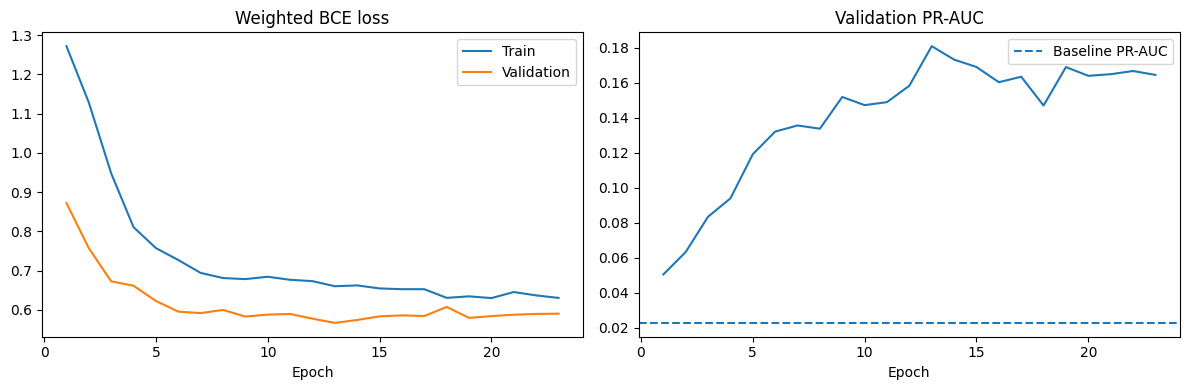


Model and training artifacts saved.
MLP Test Accuracy: 94.65%


In [ ]:

# MLP with validation only

import copy
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

torch.manual_seed(42)
np.random.seed(42)

processed = REPO_DIR / "data" / "processed"

train = pd.read_csv(processed / "train.csv")
val = pd.read_csv(processed / "val.csv")

with open(processed / "feature_columns.json") as f:
    feature_columns = json.load(f)

#standardize using the training statistics only
scaler = StandardScaler()

X_train = scaler.fit_transform(
    train[feature_columns]
).astype("float32")

X_val = scaler.transform(
    val[feature_columns]
).astype("float32")

y_train = train["label"].to_numpy(dtype="float32")
y_val = val["label"].to_numpy(dtype="float32")

# tensor prep
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_train),
        torch.from_numpy(y_train).unsqueeze(1)
    ),
    batch_size=256,
    shuffle=True
)

X_val_t = torch.from_numpy(X_val).to(device)
y_val_t = torch.from_numpy(y_val).unsqueeze(1).to(device)

#  NN build
model = nn.Sequential(
    nn.Linear(len(feature_columns), 32),
    nn.ReLU(),
    nn.Dropout(0.15),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
).to(device)

# weight train
n_positive = int(y_train.sum())
n_negative = len(y_train) - n_positive

pos_weight = n_negative / n_positive

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([pos_weight], device=device)
)

optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

# train with early stopping
history = []
best_ap = -1
best_state = None
best_epoch = 0
patience = 0

for epoch in range(1, 61):
    model.train()
    total_loss = 0

    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    train_loss = total_loss / len(train)

    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t).item()
        val_probs = torch.sigmoid(
            val_logits
        ).cpu().numpy().ravel()

    val_ap = average_precision_score(y_val, val_probs)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_ap": val_ap
    })

    if val_ap > best_ap + 1e-5:
        best_ap = val_ap
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch
        patience = 0
    else:
        patience += 1

    if epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val PR-AUC: {val_ap:.4f}"
        )

    if patience >= 10:
        print("Early stopping triggered.")
        break

# get best model
model.load_state_dict(best_state)
model.eval()

with torch.no_grad():
    val_probs = torch.sigmoid(
        model(X_val_t)
    ).cpu().numpy().ravel()

# classification based on only validation
precision, recall, thresholds = precision_recall_curve(
    y_val, val_probs
)

f1_values = (
    2 * precision[:-1] * recall[:-1]
    / np.maximum(precision[:-1] + recall[:-1], 1e-12)
)

best_index = np.argmax(f1_values)
best_threshold = float(thresholds[best_index])
val_pred = (val_probs >= best_threshold).astype(int)

print("\n===== BEST MODEL — VALIDATION =====")
print("Best epoch:", best_epoch)
print("Class positive weight:", round(pos_weight, 2))
print("Validation threshold:", round(best_threshold, 4))
print("PR-AUC:", round(average_precision_score(y_val, val_probs), 4))
print("Precision:", round(precision_score(y_val, val_pred), 4))
print("Recall:", round(recall_score(y_val, val_pred), 4))
print("F1:", round(f1_score(y_val, val_pred), 4))

# Plots
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"],
             label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"],
             label="Validation")
axes[0].set_title("Weighted BCE loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["val_ap"])
axes[1].axhline(
    y_val.mean(), linestyle="--",
    label="Baseline PR-AUC"
)
axes[1].set_title("Validation PR-AUC")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# save info
torch.save(best_state, processed / "mlp_best.pt")
joblib.dump(scaler, processed / "feature_scaler.joblib")
history_df.to_csv(processed / "training_history.csv", index=False)

with open(processed / "mlp_config.json", "w") as f:
    json.dump({
        "best_epoch": best_epoch,
        "threshold": best_threshold,
        "feature_columns": feature_columns
    }, f, indent=2)

print("\nModel and training artifacts saved.")
print(f"MLP Test Accuracy: {accuracy_score(y_test, predictions) * 100:.2f}%")

In [ ]:
# error analysis

import numpy as np
import pandas as pd

processed = REPO_DIR / "data" / "processed"
errors = pd.read_csv(processed / "test_predictions.csv")

conditions = [
    (errors["label"] == 1) & (errors["mlp_prediction"] == 1),
    (errors["label"] == 0) & (errors["mlp_prediction"] == 1),
    (errors["label"] == 1) & (errors["mlp_prediction"] == 0),
    (errors["label"] == 0) & (errors["mlp_prediction"] == 0)
]

errors["outcome"] = np.select(
    conditions,
    ["TP", "FP", "FN", "TN"],
    default="Unknown"
)

errors["gap_range"] = pd.cut(
    errors["gap_seconds"],
    bins=[0, 0.5, 1, 2, 3.001],
    labels=["0–0.5s", "0.5–1s", "1–2s", "2–3s"]
)

print("===== ERRORS BY GAP =====")
display(pd.crosstab(errors["gap_range"], errors["outcome"]))

print("\n===== HIGHEST-CONFIDENCE FALSE POSITIVES =====")
display(
    errors[errors["outcome"] == "FP"]
    .sort_values("mlp_score", ascending=False)
    [[
        "time", "driver_number", "driver_ahead",
        "gap_seconds", "relative_speed_mean", "mlp_score"
    ]]
    .head(10)
)

print("\n===== MISSED POSITIVES =====")
display(
    errors[errors["outcome"] == "FN"]
    .sort_values("mlp_score", ascending=False)
    [[
        "time", "driver_number", "driver_ahead",
        "gap_seconds", "relative_speed_mean", "mlp_score"
    ]]
    .head(10)
)

errors.to_csv(
    processed / "test_error_analysis.csv",
    index=False
)

===== ERRORS BY GAP =====


outcome,FN,FP,TN,TP
gap_range,,,,
0–0.5s,13,93,120,23
0.5–1s,44,34,1407,2
1–2s,19,0,1287,0
2–3s,5,0,844,0



===== HIGHEST-CONFIDENCE FALSE POSITIVES =====


,time,driver_number,driver_ahead,gap_seconds,relative_speed_mean,mlp_score
1408,2024-11-03 16:12:07.515000+00:00,27,14,0.466,23.819820,0.997614
1389,2024-11-03 16:11:57.515000+00:00,27,14,0.907,28.929204,0.995798
2085,2024-11-03 16:22:27.515000+00:00,55,43,0.351,30.037037,0.995191
2682,2024-11-03 17:25:07.515000+00:00,4,16,0.368,25.612069,0.992891
2006,2024-11-03 16:21:07.515000+00:00,11,55,0.469,19.796296,0.991305
1989,2024-11-03 16:20:57.515000+00:00,11,55,0.354,14.882883,0.987209
1418,2024-11-03 16:12:17.515000+00:00,27,14,0.576,16.394737,0.985101
2670,2024-11-03 17:24:57.515000+00:00,4,16,0.448,8.236842,0.972836
2072,2024-11-03 16:22:17.515000+00:00,55,43,0.505,7.619048,0.966015
43,2024-11-03 15:52:17.515000+00:00,27,50,0.324,1.348214,0.962050



===== MISSED POSITIVES =====


,time,driver_number,driver_ahead,gap_seconds,relative_speed_mean,mlp_score
971,2024-11-03 16:04:37.515000+00:00,1,30,0.468,-0.629630,0.860531
2265,2024-11-03 17:05:37.515000+00:00,50,24,0.631,5.711712,0.841653
2471,2024-11-03 17:20:07.515000+00:00,50,24,0.105,-0.303571,0.840237
188,2024-11-03 15:53:47.515000+00:00,55,24,0.648,-1.027523,0.829368
2239,2024-11-03 17:05:17.515000+00:00,63,4,0.267,-0.229358,0.828388
3410,2024-11-03 17:40:47.515000+00:00,14,24,0.429,1.727273,0.789699
317,2024-11-03 15:56:47.515000+00:00,27,43,0.629,7.355932,0.784522
2470,2024-11-03 17:20:07.515000+00:00,1,31,0.097,3.008929,0.777262
1616,2024-11-03 16:15:17.515000+00:00,55,44,0.665,4.025641,0.765507
344,2024-11-03 15:57:17.515000+00:00,1,14,0.643,-4.422414,0.752012
